## Чтение файла

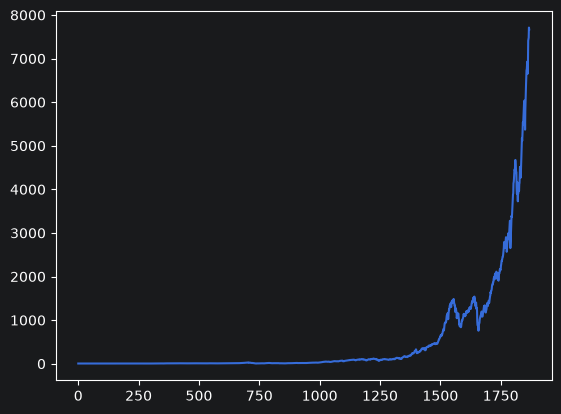

In [72]:
import matplotlib.pyplot as plt
import numpy as np

data = []

with open('data.csv', 'r') as f:
    for line in f:
        data.append(line.split(',')[1])

data = np.array(data[1:], dtype=float)

plt.plot(data)
plt.show()

## Разделение данных на 3 датасета и преобразование Бокса-Кокса

In [73]:
from scipy.stats import boxcox

n = len(data)
i_train = int(n * 0.7)
i_val = int(n * 0.9)

_, lam = boxcox(data[:i_train])
bc = boxcox(data, lmbda=lam)
d = np.diff(bc)

train = d[:i_train - 1]
val = d[i_train - 1:i_val - 1]
test = d[i_val - 1:]

## Обучаем модель с наименьшей ошибкой

In [74]:
from statsmodels.tsa.ar_model import AutoReg

def predict_one_step(res, p, start, end):
    c, phi = res.params[0], res.params[1:]
    return np.array([c + np.sum(phi * d[t - p:t][::-1]) for t in range(start, end)])

best_err = np.inf
for p in range(1, 31):
    res = AutoReg(train, lags=p).fit()
    pred = predict_one_step(res, p, i_train - 1, i_val - 1)
    err = np.sqrt(np.mean((pred - val) ** 2))
    if err < best_err:
        best_err, best_p, best_res = err, p, res

p, res = best_p, best_res

print('p =', p, '\nRMSE =', best_err)

p = 5 
RMSE = 0.002230534617296467


## Отображение авторегрессии и сравнение с данными

p = 5, MAE: AR = 86.25474779222165, naive = 86.19370056765634


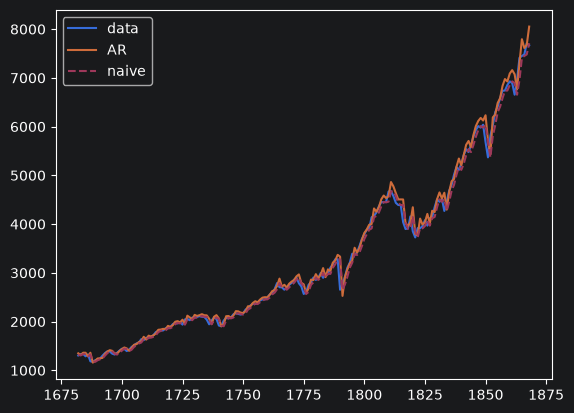

In [76]:
from scipy.special import inv_boxcox

pred_test = predict_one_step(res, p, i_val - 1, len(d))
forecast = inv_boxcox(bc[i_val - 1:-1] + pred_test, lam)
naive = data[i_val - 1:-1]

print(f'p = {p}, MAE: AR = {np.mean(np.abs(forecast - data[i_val:]))}, naive = {np.mean(np.abs(naive - data[i_val:]))}')

x = np.arange(i_val, n)
plt.plot(x, data[i_val:], label='data')
plt.plot(x, forecast, label='AR')
plt.plot(x, naive, '--', label='naive')
plt.legend()
plt.show()